In [ ]:
# Data Visualization

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display the first 5 rows
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

In [ ]:
df.shape

(6433, 14)

In [ ]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


In [ ]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


In [ ]:
# Handling Missing Values

# Handling Missing Values

# 1.Check for missing values

In [ ]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


2.2 Impute missing values

In [ ]:
# Identify numerical columns
numeric_cols = df.select_dtypes(include='number').columns

# Fill missing numerical values with the median
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

In [ ]:
# Identify categorical columns
categorical_cols = df.select_dtypes(include='object').columns

# Fill missing categorical values with the mode
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

2.3 Remove rows with
missing values

In [ ]:
# Remove rows with any remaining missing values
df = df.dropna()

In [ ]:
# Check whether any missing values remain
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


# 3.Visualizations using Matplotlib/Pandas Plot

3.1 Line Chart

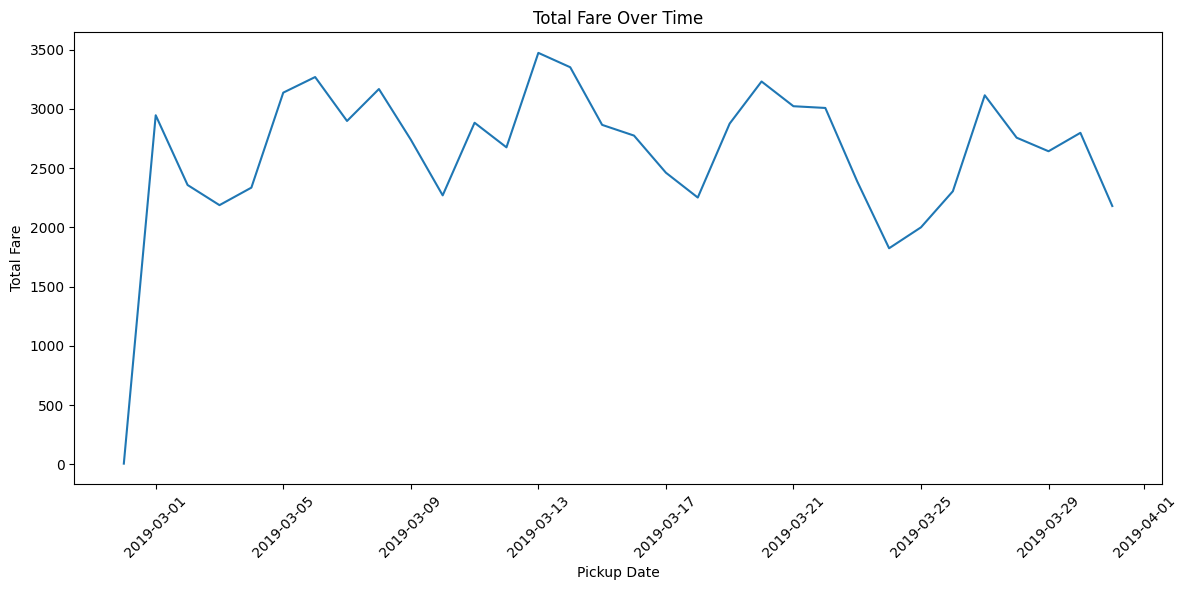

In [ ]:
# Group total fare by pickup date
daily_fare = df.groupby(df['pickup'].dt.date)['fare'].sum()

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(daily_fare.index, daily_fare.values)

plt.xlabel('Pickup Date')
plt.ylabel('Total Fare')
plt.title('Total Fare Over Time')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:
import pandas as pd
df['pickup'] = pd.to_datetime(df['pickup'])

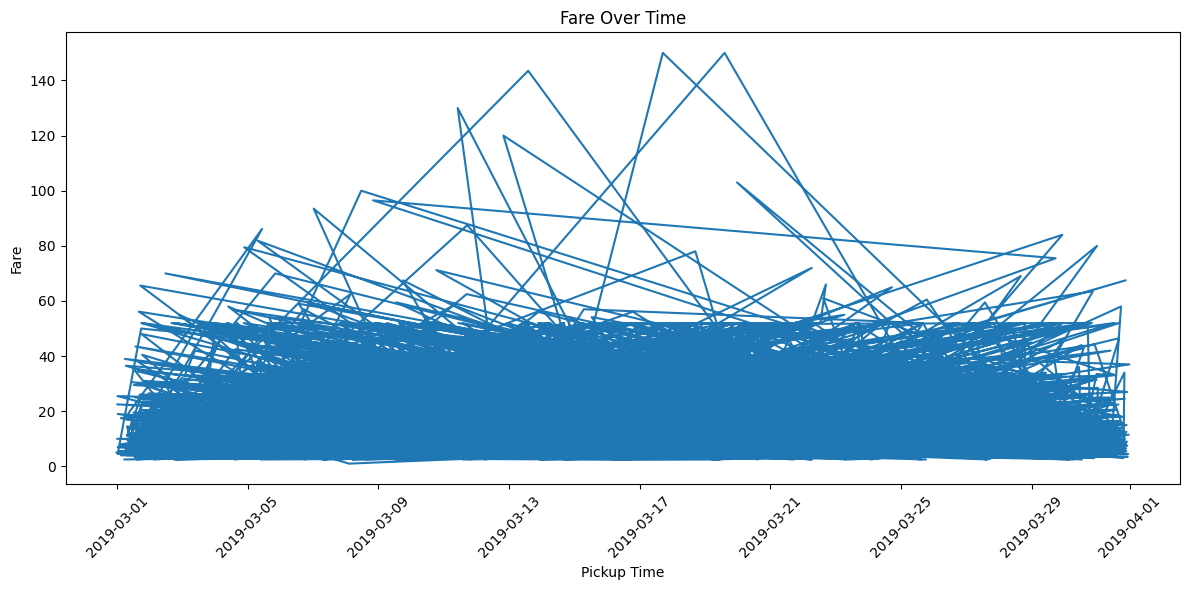

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(df['pickup'], df['fare'])

plt.xlabel('Pickup Time')
plt.ylabel('Fare')
plt.title('Fare Over Time')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

3.2 Bar Chart

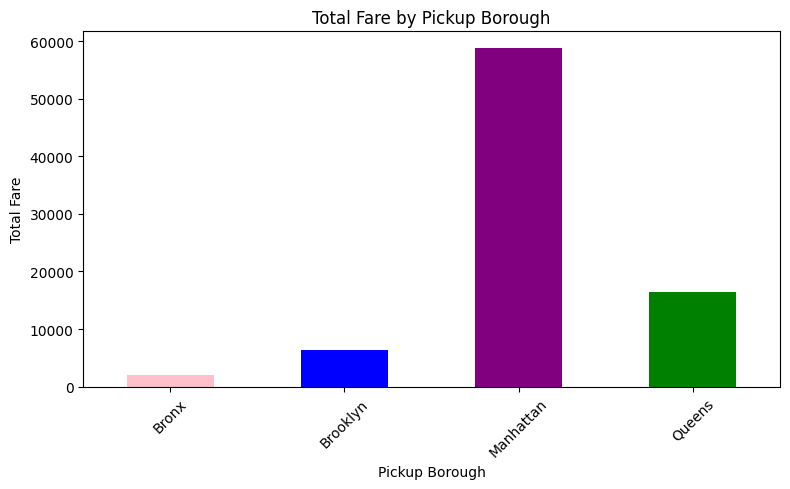

In [ ]:
fare_by_borough = df.groupby('pickup_borough')['fare'].sum()

plt.figure(figsize=(8, 5))

fare_by_borough.plot(kind='bar', color=['pink','blue','purple','green'])

plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.title('Total Fare by Pickup Borough')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

3.3 Pie Chart

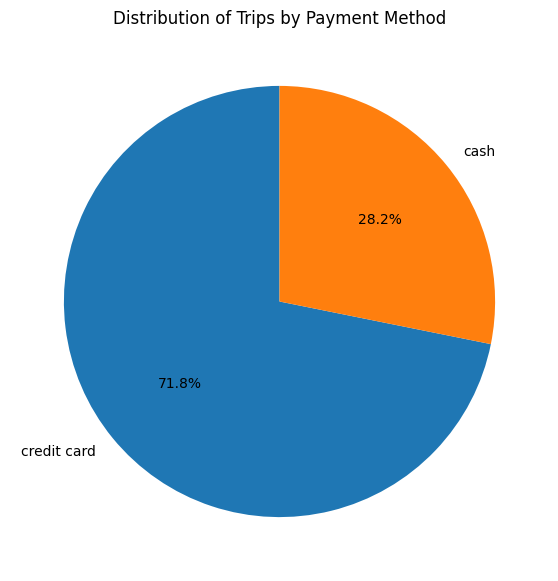

In [ ]:
payment_counts = df['payment'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Trips by Payment Method')
plt.show()

3.4 Histogram

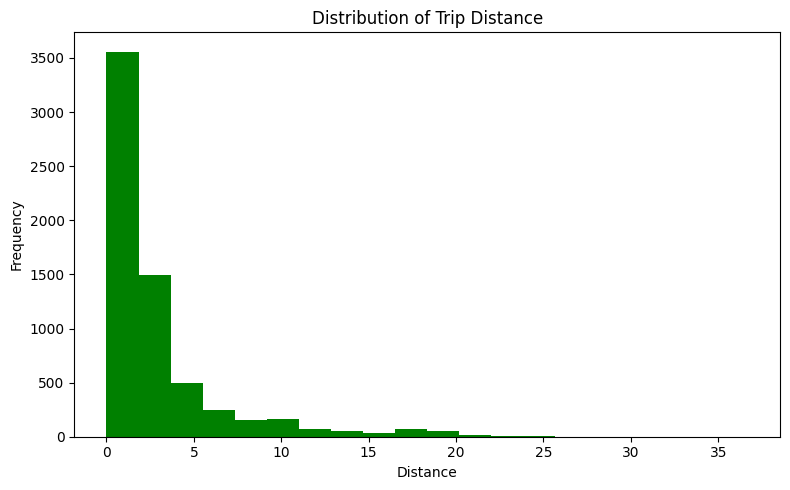

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df['distance'], bins=20,color ='Green')

plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.title('Distribution of Trip Distance')

plt.tight_layout()
plt.show()

3.5 Box Plot

<Figure size 1000x600 with 0 Axes>

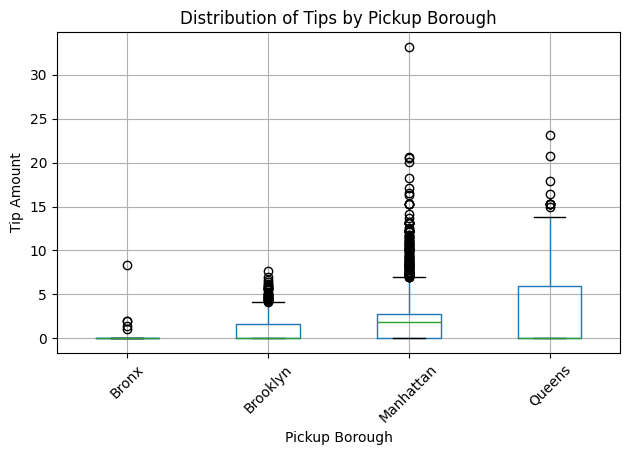

In [ ]:
plt.figure(figsize=(10, 6))

df.boxplot(column='tip', by='pickup_borough')

plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.title('Distribution of Tips by Pickup Borough')

plt.suptitle('')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# 4: Visualizations using Seaborn

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

4.1 Count Plot — Trips by Pickup Borough

/tmp/ipykernel_2169/2996051301.py:3: UserWarning: The palette list has more values (5) than needed (4), which may not be intended.
  sns.countplot(data=df, x='pickup_borough',hue='pickup_borough',palette=['pink', 'skyblue', 'green', 'orange', 'purple'],


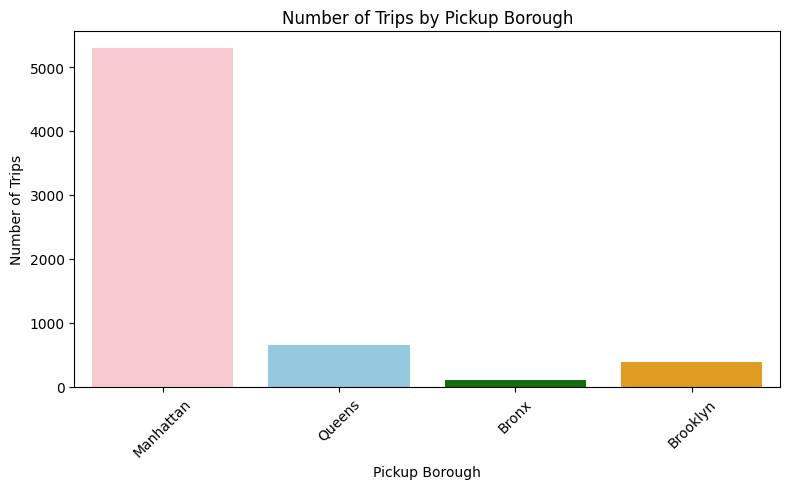

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='pickup_borough',hue='pickup_borough',palette=['pink', 'skyblue', 'green', 'orange', 'purple'],
    legend=False)

plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.title('Number of Trips by Pickup Borough')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

4.2 Scatter Plot — Distance vs Fare

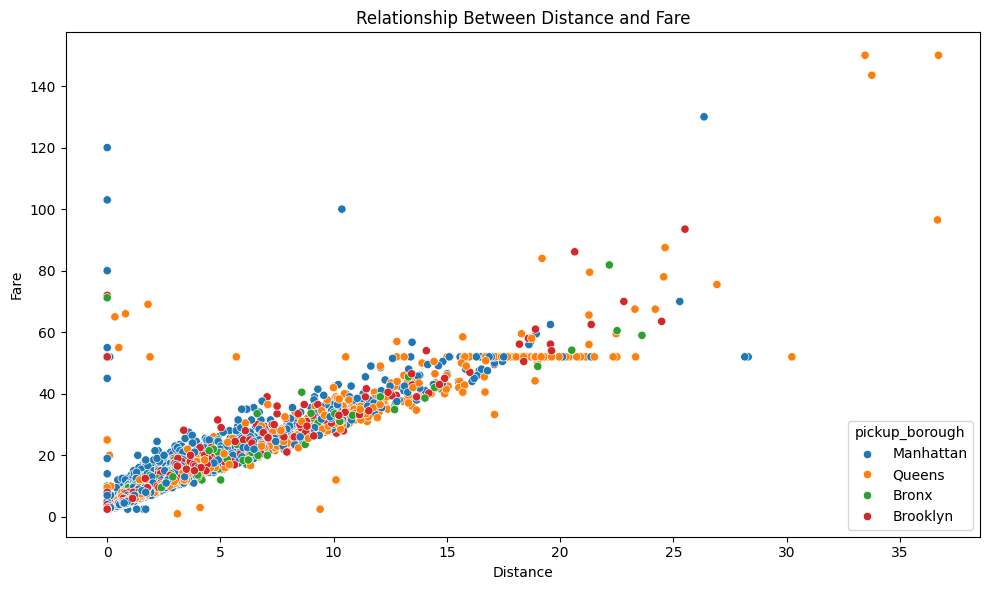

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.xlabel('Distance')
plt.ylabel('Fare')
plt.title('Relationship Between Distance and Fare')

plt.tight_layout()
plt.show()

4.3 Heatmap — Correlation Between Numerical Variables

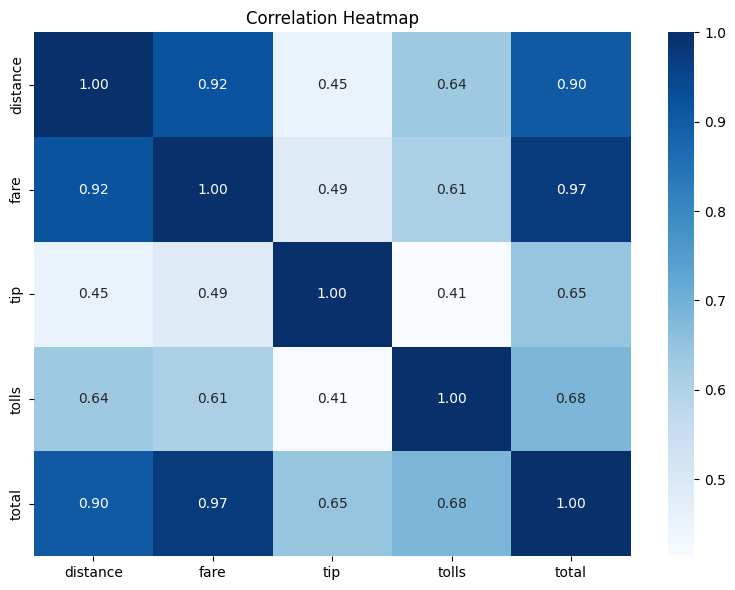

In [ ]:
correlation = df[['distance', 'fare', 'tip', 'tolls', 'total']].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='Blues',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()

4.4 Pair Plot — Distance, Fare, Tip and Total

/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:1513: UserWarning: 
The palette list has fewer values (5) than needed (194) and will cycle, which may produce an uninterpretable plot.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:1513: UserWarning: 
The palette list has fewer values (5) than needed (194) and will cycle, which may produce an uninterpretable plot.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:1513: UserWarning: 
The palette list has fewer values (5) than needed (194) and will cycle, which may produce an uninterpretable plot.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:1513: UserWarning: 
The palette list has fewer values (5) than needed (194) and will cycle, which may produce an uninterpretable plot.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:1615: UserWarning: 
The palette 

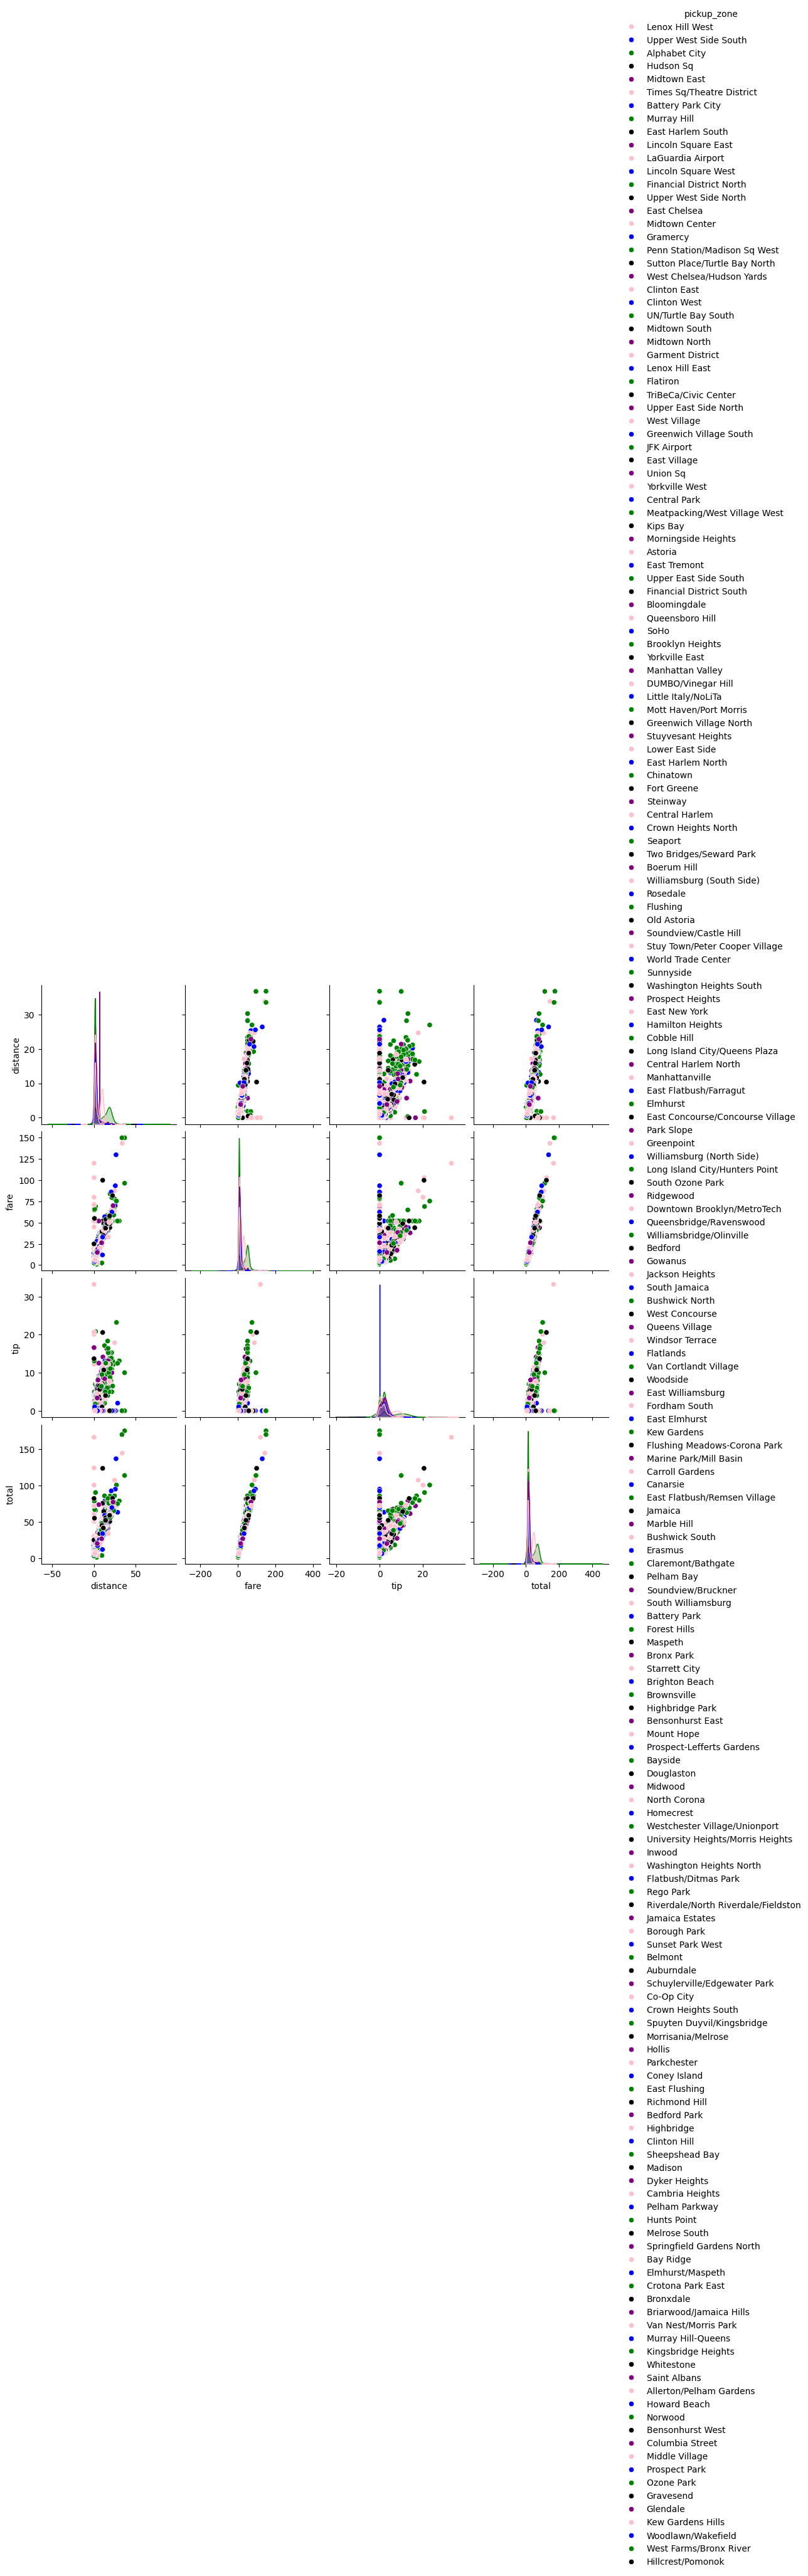

In [ ]:
sns.pairplot(
    df[['distance', 'fare', 'tip', 'total', 'pickup_zone']].dropna(),
    hue='pickup_zone',
    palette=['pink', 'blue', 'green', 'black', 'purple']
)

plt.show()

4.5 Violin Plot — Fare by Payment Method

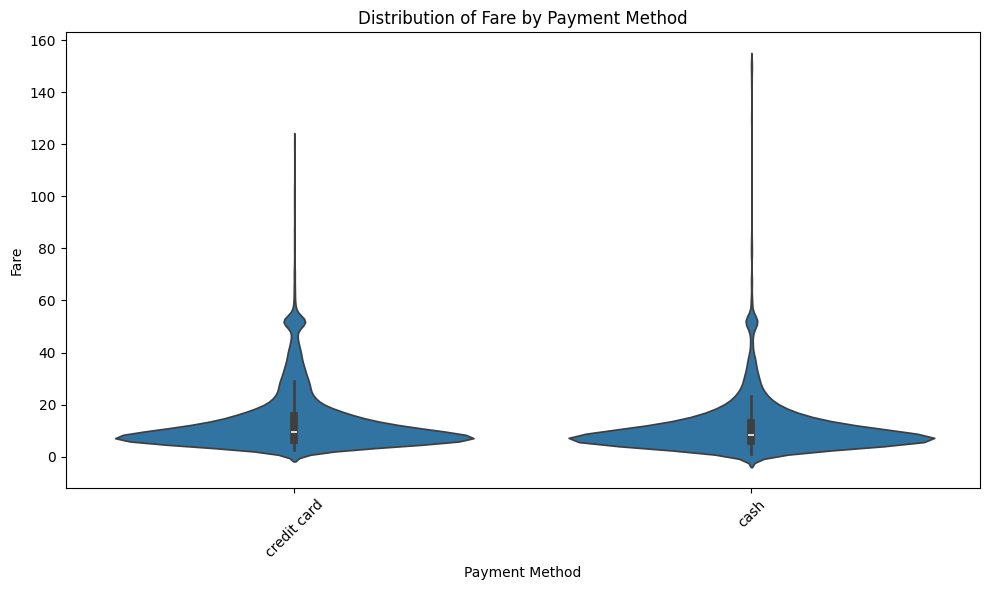

In [ ]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='payment',
    y='fare'
)

plt.xlabel('Payment Method')
plt.ylabel('Fare')
plt.title('Distribution of Fare by Payment Method')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()